In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import librosa
import pretty_midi


In [3]:
transform = transforms.ToTensor() #transforms image to tensor

# transform = transforms.Compose(
#     [
#         transforms.ToTensor(),
#         transforms.Normalize((0.5), (0.5))                            
#     ]
# )

mnist_data = datasets.MNIST(root= './data', train= True, download= True, transform=transform)

data_loader = torch.utils.data.DataLoader(dataset=mnist_data, batch_size=64, shuffle=True)


In [4]:
dataiter = iter(data_loader)
images, labels = next(dataiter)
print(torch.min(images), torch.max(images))  # images contain values in the range [0, 1] gray scale images

tensor(0.) tensor(1.)


In [5]:
print(images,labels)

tensor([[[[0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          ...,
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.]]],


        [[[0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          ...,
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.]]],


        [[[0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          ...,
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.]]],


        ...,


        [[[0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          ...,
          [0., 0., 0.,  ..., 0.

In [6]:
class Autoencoder_Linear(nn.Module):
    def __init__(self):
        super().__init__()
        # N,784 
        self.encoder = nn.Sequential(
            nn.Linear(28*28,128), # N,784 -> N,128
            nn.ReLU(),
            nn.Linear(128,64),
            nn.ReLU(),
            nn.Linear(64, 12),
            nn.ReLU(),
            nn.Linear(12, 3)
            )
        self.decoder = nn.Sequential(
            nn.Linear(3,12), # N,3 -> N,784
            nn.ReLU(),
            nn.Linear(12,64),
            nn.ReLU(),
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Linear(128, 784),
            nn.Sigmoid()  # he have to use sigmoid because the data is normalized to [0,1]

                    )
    def forward(self,x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded
    
#|Note  [-1,1] -> nn.Tanh should be used when we normalize the data additionally in the transform

In [7]:
class Autoencoder_Convolutional(nn.Module):
    def __init__(self):
        super().__init__()        
        # N, 1, 28, 28
        self.encoder = nn.Sequential(
            
            nn.Conv2d(1, 16, 3, stride=2, padding=1), # -> N, 16, 14, 14
            nn.ReLU(),
            nn.MaxPool2d(2,2),# N, 16,  7, 7
            nn.Conv2d(16, 32, 3, stride=2, padding=1), # -> N, 32, 4, 4
            nn.ReLU(),
            nn.MaxPool2d(2,2),
            nn.Conv2d(32, 64, 2) # -> N, 64, 1, 1
        )
        
        # N , 64, 1, 1
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(64, 32, 7), # -> N, 32, 7, 7
            nn.ReLU(),
            
            nn.ConvTranspose2d(32, 16, 3, stride=2, padding=1, output_padding=1), # N, 16, 14, 14 (N,16,13,13 without output_padding)
            nn.ReLU(),
           
            nn.ConvTranspose2d(16, 1, 3, stride=2, padding=1, output_padding=1), # N, 1, 28, 28  (N,1,27,27)
            nn.Sigmoid()
        )
    def forward(self,x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded
    
#|Note  [-1,1] -> nn.Tanh should be used when we normalize the data additionally in the transform
# w konwolucjach uzywa sie czesto nn.MaxPool2d -> nn.MaxUnPool2d 

In [8]:
model = Autoencoder_Convolutional()
critierion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr= 1e-3, weight_decay=1e-5)

In [9]:
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))

True
NVIDIA GeForce RTX 2060


In [10]:
num_epochs = 10
outputs = []

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = model.to(device)

for epoch in range(num_epochs):
    for (img, _) in data_loader:
        # img = img.reshape(-1, 28*28)
        img = img.to(device)
        recon = model(img)
        loss = critierion(recon, img)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    print(f'Epoch {epoch+1}, loss: {loss.item():.4f}')
    outputs.append((epoch, img, recon))

Epoch 1, loss: 0.0213
Epoch 2, loss: 0.0159
Epoch 3, loss: 0.0098
Epoch 4, loss: 0.0100
Epoch 5, loss: 0.0084
Epoch 6, loss: 0.0081
Epoch 7, loss: 0.0065
Epoch 8, loss: 0.0064
Epoch 9, loss: 0.0056
Epoch 10, loss: 0.0063


## Visualization of the reconstructed images

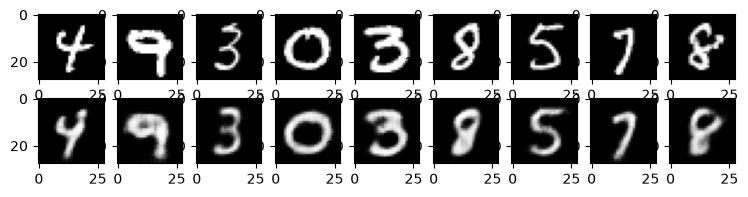

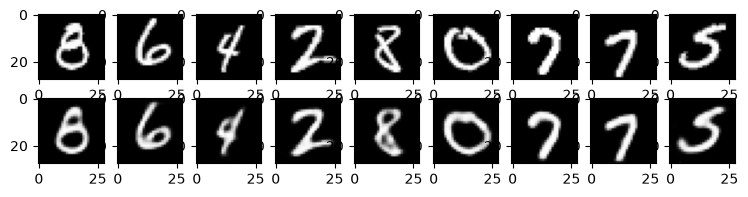

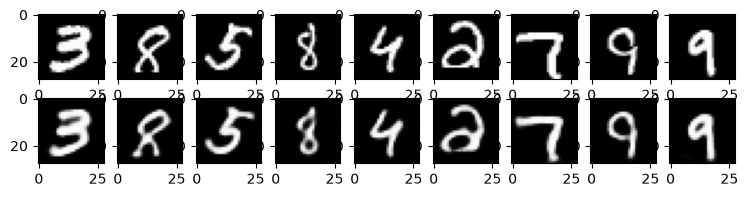

In [11]:


for k in range(0, num_epochs, 4):
    plt.figure(figsize=(9, 2))
    plt.gray()
    imgs = outputs[k][1].detach().cpu().numpy()
    recon = outputs[k][2].detach().cpu().numpy()
    for i, item in enumerate(imgs):
        if i >= 9: break
        plt.subplot(2, 9, i+1)
        # item = item.reshape(-1, 28,28) # -> use for Autoencoder_Linear
        # item: 1, 28, 28
        plt.imshow(item[0])
            
    for i, item in enumerate(recon):
        if i >= 9: break
        plt.subplot(2, 9, 9+i+1) # row_length + i + 1
        # item = item.reshape(-1, 28,28) # -> use for Autoencoder_Linear
        # item: 1, 28, 28
        plt.imshow(item[0])

## Latent space visualization


In [12]:
class Autoencoder_Latent(nn.Module):
    def __init__(self):
        super().__init__()
        # N,784 
        self.encoder = nn.Sequential(
            nn.Linear(28*28,128), # N,784 -> N,128
            nn.ReLU(),
            nn.Linear(128,64),
            nn.ReLU(),
            nn.Linear(64, 12),
            nn.ReLU(),
            nn.Linear(12, 2) #output latent space dimension has been changed to 2 due to latent space visualization purposes
            )
        self.decoder = nn.Sequential(
            nn.Linear(2,12), # N,2 -> N,784
            nn.ReLU(),
            nn.Linear(12,64),
            nn.ReLU(),
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Linear(128, 784),
            nn.Sigmoid() 
        )

    def forward(self,x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

In [13]:
model_latent = Autoencoder_Latent()
critierion = nn.MSELoss()
optimizer = torch.optim.Adam(model_latent.parameters(), lr= 1e-3, weight_decay=1e-5)

In [14]:
num_epochs = 10
outputs = []

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_latent = model_latent.to(device)

for epoch in range(num_epochs):
    for (img, lab) in data_loader:
        img = img.reshape(-1, 28*28)
        img = img.to(device)
        labels = lab.to(device)
        recon = model_latent(img)
        # print(recon.shape)
        # print(img.shape)
        loss = critierion(recon, img)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    print(f'Epoch {epoch+1}, loss: {loss.item():.4f}')
    outputs.append((epoch, img, recon, labels))

Epoch 1, loss: 0.0567
Epoch 2, loss: 0.0476
Epoch 3, loss: 0.0493
Epoch 4, loss: 0.0436
Epoch 5, loss: 0.0551
Epoch 6, loss: 0.0426
Epoch 7, loss: 0.0434
Epoch 8, loss: 0.0404
Epoch 9, loss: 0.0411
Epoch 10, loss: 0.0404


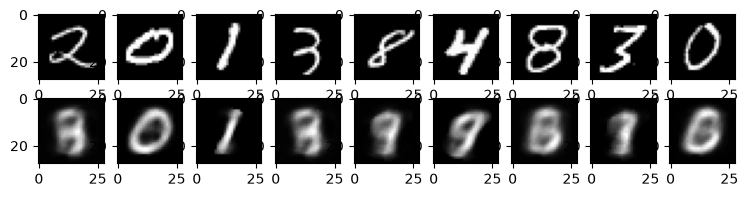

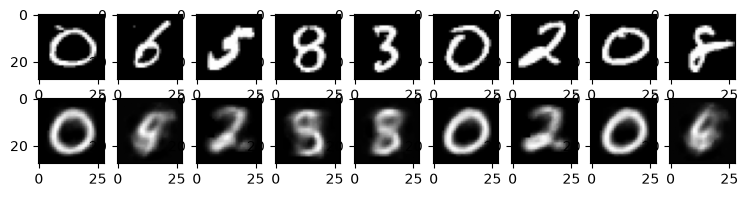

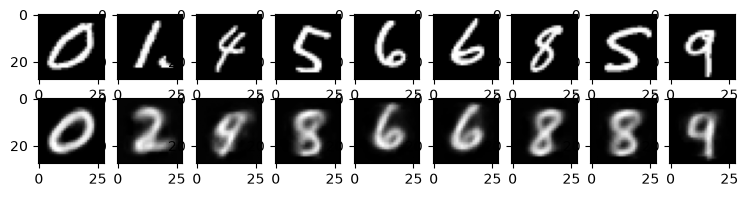

In [15]:
for k in range(0, num_epochs, 4):
    plt.figure(figsize=(9, 2))
    plt.gray()
    imgs = outputs[k][1].detach().cpu().numpy()
    recon = outputs[k][2].detach().cpu().numpy()
    labels = outputs[k][3].detach().cpu().numpy()
    for i, item in enumerate(imgs):
        if i >= 9: 
            break
        plt.subplot(2, 9, i+1)
        item = item.reshape(-1, 28,28) # -> use for Autoencoder_Linear
        # item: 1, 28, 28
        plt.imshow(item[0])
            
    for i, item in enumerate(recon):
        if i >= 9: 
            break
        plt.subplot(2, 9, 9+i+1)
        item = item.reshape(-1, 28,28) # -> use for Autoencoder_Linear
        # item: 1, 28, 28
        plt.imshow(item[0])


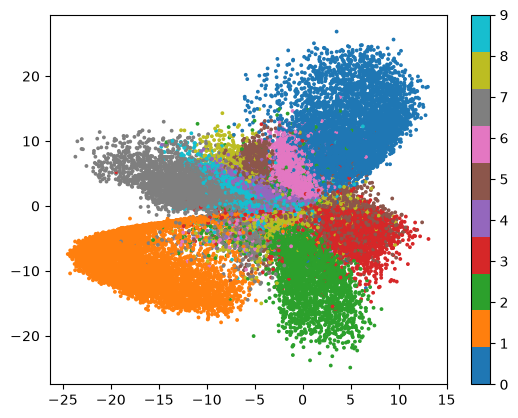

In [16]:
import numpy as np
activation = {}
def get_activation(name):
    def hook(model,input, output):
        activation[name] = output.detach()
    return hook
model_latent.encoder[6]._forward_hooks.clear()
model_latent.encoder[6].register_forward_hook(get_activation(model_latent.encoder[6]))



x = img

imgs_ag = []
labs_ag = []

model_latent.eval()
with torch.no_grad():
    for (img, lab) in data_loader:
        img = img.reshape(-1, 28*28).to(device)
        z = model_latent.encoder(img)
        imgs_ag.append(z.cpu().numpy())
        labs_ag.append(lab.cpu().numpy())
        
    punkty = np.concatenate(imgs_ag ,axis=0)

    cyfry = np.concatenate(labs_ag, axis=0)
        
    

plt.scatter(punkty[:,0], punkty[:,1], c= cyfry , cmap='tab10', s= 3)
plt.colorbar()


## Comparison between 2D PCA and 2D Autoencoder

 

[0.09704395 0.07096099]


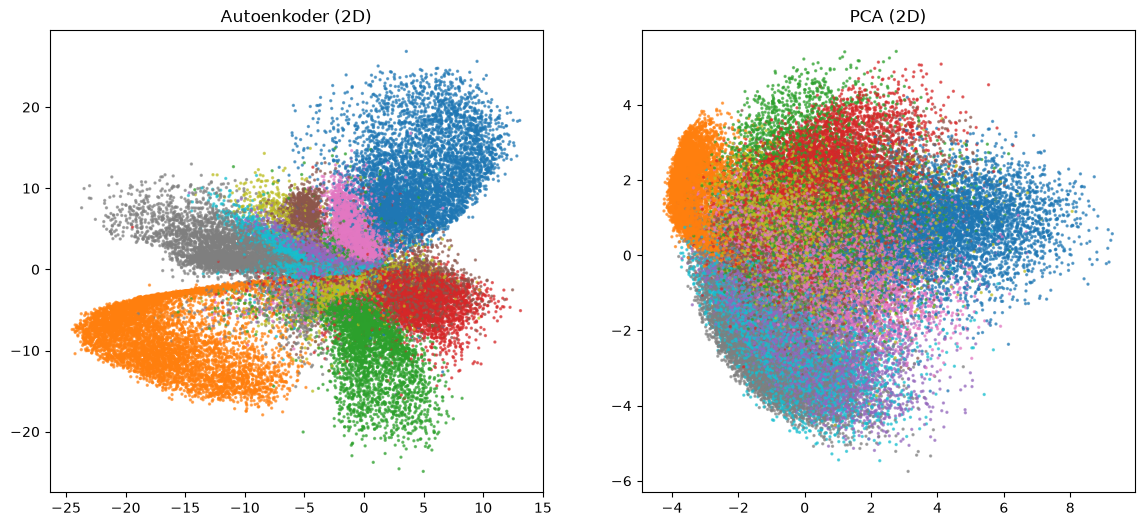

In [17]:
from sklearn.decomposition import PCA


imgs_lista, cyfry_lista = [], []
for img, lab in data_loader:
    imgs_lista.append(img.reshape(-1, 28*28).numpy())
    cyfry_lista.append(lab.numpy())

X = np.concatenate(imgs_lista, axis=0)      # (60000, 784)
y = np.concatenate(cyfry_lista, axis=0)     # (60000,)

pca = PCA(n_components=2)   # 2 components oznacza 2 wymiary, czyli 2 kierunki w których PCA będzie szukało największej wariancji danych
Z = pca.fit_transform(X)                    
print(pca.explained_variance_ratio_)        # ile "informacji" łapią te 2 kierunki

#wykres obok autoenkodera
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
ax[0].scatter(punkty[:, 0], punkty[:, 1], c=cyfry, cmap="tab10", s=2, alpha=0.6)
ax[0].set_title("Autoenkoder (2D)")
ax[1].scatter(Z[:, 0], Z[:, 1], c=y, cmap="tab10", s=2, alpha=0.6)
ax[1].set_title("PCA (2D)")

plt.show()

## VAE - variational autoencoder

In [40]:
class VarAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.num_hidden = 8
        self.mu = nn.Linear(self.num_hidden,self.num_hidden)
        self.log_var = nn.Linear(self.num_hidden,self.num_hidden)

            # N,784 
        self.encoder = nn.Sequential(
            nn.Linear(28*28,128), # N,784 -> N,128
            nn.ReLU(),
            nn.Linear(128,64),
            nn.ReLU(),
            nn.Linear(64, 12),
            nn.ReLU(),
            nn.Linear(12, self.num_hidden) #output latent space dimension 2 due to visualization purposes
            )



        self.decoder = nn.Sequential(
            nn.Linear(self.num_hidden,12), # N,2 -> N,784
            nn.ReLU(),
            nn.Linear(12,64),
            nn.ReLU(),
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Linear(128, 784),
            nn.Sigmoid() 
        )
    def reparameterize(self, mu, log_var):
        #getting standard deviation from log variance
        std = torch.exp(0.5*log_var) 
        #generating noise that has the same distribution as std
        eps = torch.rand_like(std)
        #combining reparameterize sample
        return mu +  eps * std
        
        



    def forward(self,x):
        encoded = self.encoder(x)

        mu = self.mu(encoded)
        log_var = self.log_var(encoded)

        z = self.reparameterize(mu, log_var)
        
        decoded = self.decoder(z)
        return encoded, decoded, mu, log_var


    def sample(self,num_samples):
        with torch.no_grad():
            #random noise
            z = torch.randn(num_samples, self.num_hidden).to(device)

            samples = self.decoder(z)

        return samples

model_vae = VarAutoencoder()

In [41]:
def loss_function(recon_x, x, mu, logvar):
    BCE = F.binary_cross_entropy(recon_x, x.view(-1, 784), reduction='sum')
    KLD = -0.5 * torch.sum(1+logvar - mu.pow(2) - logvar.exp()) 
    return BCE + KLD

# mnist_data = datasets.MNIST(root= './data', train= True, download= True, transform=transform)

# data_loader = torch.utils.data.DataLoader(dataset=mnist_data, batch_size=64, shuffle=True)


Dataset MNIST
    Number of datapoints: 60000
    Root location: ./data
    Split: Train
    StandardTransform
Transform: ToTensor()

In [42]:
num_epochs = 10
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_vae = model_vae.to(device)
optimizer = optim.Adam(model_vae.parameters(), lr=1e-3)

for epoch in range(num_epochs):
    total_loss = 0.0

    for images, _ in data_loader:
        data = images.view(-1, 28 * 28).to(device)

        _, decoded, mu, log_var = model_vae(data)
        loss = loss_function(decoded, data, mu, log_var)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch + 1}, loss: {total_loss / len(mnist_data):.4f}")

Epoch 1, loss: 188.6631
Epoch 2, loss: 151.2599
Epoch 3, loss: 141.0229
Epoch 4, loss: 135.0195
Epoch 5, loss: 129.4606
Epoch 6, loss: 126.5109
Epoch 7, loss: 123.1863
Epoch 8, loss: 121.1341
Epoch 9, loss: 119.6999
Epoch 10, loss: 118.5727


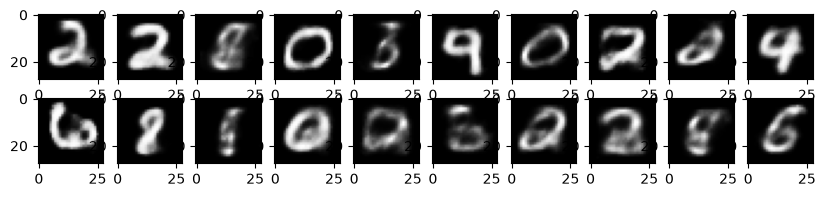

In [55]:
model_vae.sample(20).view(-1, 1, 28, 28).cpu().numpy()


plt.figure(figsize=(10, 2))
for i in range(20):
    labels = model_vae.sample(1).view(-1, 28, 28).cpu().numpy()[0]

    plt.subplot(2, 10, i + 1)
    plt.imshow(model_vae.sample(1).view(-1, 28, 28).cpu().numpy()[0],  cmap='gray')
    



## Interpolation

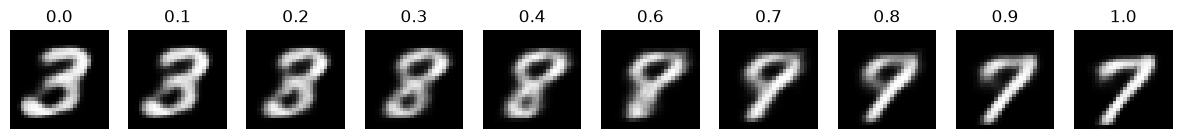

In [ ]:
mnist_data = datasets.MNIST(
    root="./data", train=True, download=True, transform=transforms.ToTensor()
)
data_loader = torch.utils.data.DataLoader(
    mnist_data, batch_size=64, shuffle=False
)

def find_digit(digit):
    for images, labels in data_loader:
        matches = (labels == digit).nonzero(as_tuple=True)[0]
        if len(matches) > 0:
            return images[matches[0]]
    raise ValueError(f"Nie znaleziono cyfry {digit}")

image_a = find_digit(3)
image_b = find_digit(7)
#
x_a = image_a.view(1, 784).to(device)
x_b = image_b.view(1, 784).to(device)

model_vae.eval()
with torch.no_grad():
    
    mu_a = model_vae.mu(model_vae.encoder(x_a))
    mu_b = model_vae.mu(model_vae.encoder(x_b))

    # 10 points between figit a and b
    alphas = torch.linspace(0, 1, 10, device=device).unsqueeze(1)
    z_interpolated = (1 - alphas) * mu_a + alphas * mu_b

    images_interpolated = model_vae.decoder(z_interpolated).cpu().view(-1, 28, 28)

fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for i, ax in enumerate(axes):
    ax.imshow(images_interpolated[i], cmap="gray")
    ax.set_title(f"{alphas[i].item():.1f}")
    ax.axis("off")

plt.show()